# Chapter 38 - Optimising the Budget

Chapter 37 showed that Sedge's five channels sit at different points on their response curves.
This notebook turns those curves into budget plans, as Chapter 38 does: a naive optimiser with every channel free to move by 40 per cent, the risk-aware operational plan, the four plans of the book scored side by side, and the scenarios for a smaller or larger budget.

The curves come from the calibrated case-study model, one curve per posterior draw, each built from that draw's own adstock, saturation and regional scales (`case_model.posterior_curves`).
The optimiser (`greedy_allocate`, the same allocator as lab 27, with per-channel limits) runs on the average of those curves, and every plan is then scored on each draw separately.
`mmm_book.case_results.chapter38` computes the same numbers for the book's tests and figures.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from mmm_book import RANDOM_SEED
from mmm_book.case_model import fit_case_model, posterior_curves, prepare_case_data
from mmm_book.case_results import CH27_PLANS, chapter27
from mmm_book.optimise import BOOK_PLAN_ANNUAL, band, book_plan_bounds, greedy_allocate
from mmm_book.plotting import mmm_style
from mmm_book.sedge import CHANNELS, correct_distribution, generate_sedge

mmm_style()
pd.set_option("display.width", 120)
WEEKS = 52
fixed = correct_distribution(generate_sedge(seed=RANDOM_SEED))
data = prepare_case_data(fixed, "model2")
idata = fit_case_model(fixed, "model2", calibrate=True)
curves = posterior_curves(idata, data)
print(f"posterior draws behind the curves: {curves.n_draws}")


def annual(weekly):
    return {ch: weekly[ch] * WEEKS / 1e6 for ch in CHANNELS}


def weekly(annual_m):
    return {ch: annual_m[ch] * 1e6 / WEEKS for ch in CHANNELS}


def score(plan):
    gain = curves.gain_draws(plan) * WEEKS / 1e6
    lo, hi = np.quantile(gain, [0.05, 0.95])
    return {
        "gain": round(float(gain.mean()), 3),
        "5%": round(float(lo), 3),
        "95%": round(float(hi), 3),
        "chance": round(float((gain > 0).mean()), 3),
        "profit": round(float(0.5 * gain.mean()), 3),
    }


current = curves.current_money
print({ch: round(v, 2) for ch, v in annual(current).items()})
print(f"total {sum(annual(current).values()):.2f}m")

posterior draws behind the curves: 2000
{'tv': 1.4, 'search': 1.4, 'meta': 1.5, 'youtube': 0.8, 'ooh': 0.9} total 6.00m


## The naive optimiser

Every increment goes to whichever channel has the highest marginal return on the average curve, with each channel free to move by up to 40 per cent.

In [2]:
lo40, hi40 = band(curves, 0.40)
naive = greedy_allocate(curves, lo40, hi40)
print({ch: round(v, 2) for ch, v in annual(naive).items()})
print(score(naive))

{'tv': 1.96, 'search': 1.29, 'meta': 0.9, 'youtube': 1.12, 'ooh': 0.73}
{'gain': 0.582, '5%': 0.072, '95%': 1.144, 'chance': 0.971, 'profit': 0.291}


At the posterior mean the naive plan is worth about £580,000.
Scored on each draw, its gain runs from about £70,000 to £1.1 million, and much of it rests on the £320,000 added to YouTube, whose curve is among the least certain:

In [3]:
yt = curves.marginal_draws("youtube")
lo, hi = np.quantile(yt, [0.05, 0.95])
print(f"YouTube's next pound across draws: 5% {lo:.2f}, 95% {hi:.2f}")

YouTube's next pound across draws: 5% 1.03, 95% 2.75


## The risk-aware plan

The limits of Chapter 38, as annual budgets: Search between 1.30m and 1.40m, Meta between 1.20m and 1.50m, Television between 1.40m and 1.65m, YouTube from 0.80m to 0.85m and OOH from 0.90m to 0.95m (the £50,000 cap on the two channels no experiment has tested).

In [4]:
lo_b, hi_b = book_plan_bounds(curves)
optimiser = greedy_allocate(curves, lo_b, hi_b)
plan = weekly({ch: BOOK_PLAN_ANNUAL[ch] / 1e6 for ch in CHANNELS})
print("optimiser:", {ch: round(v, 2) for ch, v in annual(optimiser).items()}, score(optimiser))
print("team plan:", {ch: round(v, 2) for ch, v in annual(plan).items()}, score(plan))
for ch in ("search", "ooh"):
    print(f"{ch} marginal at current spend: {curves.marginal_return(ch):.2f}")

optimiser: {'tv': 1.65, 'search': 1.4, 'meta': 1.2, 'youtube': 0.85, 'ooh': 0.9} {'gain': 0.277, '5%': 0.102, '95%': 0.465, 'chance': 0.997, 'profit': 0.139}
team plan: {'tv': 1.65, 'search': 1.3, 'meta': 1.25, 'youtube': 0.85, 'ooh': 0.95} {'gain': 0.266, '5%': 0.11, '95%': 0.437, 'chance': 0.999, 'profit': 0.133}
search marginal at current spend: 1.39
ooh marginal at current spend: 1.39


Left to itself, the optimiser takes Meta to its floor and leaves Search and OOH alone; the team's plan takes £50,000 less from Meta and moves £50,000 from Search to OOH, two channels with the same marginal return, at a cost of about £11,000 of expected revenue.
The plan beats the current mix in more than 99 per cent of draws, with a gain between about £110,000 and £440,000.
The direction is close to certain because every draw agrees that Television's next pound earns more than Meta's:

share of draws where Television's next pound beats Meta's: 1.000


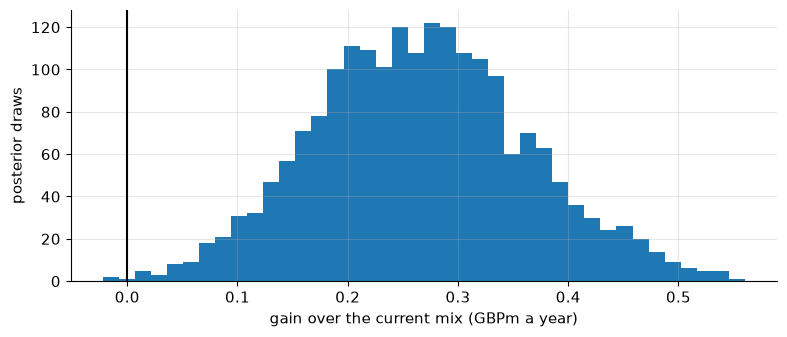

In [5]:
tv, meta = curves.marginal_draws("tv"), curves.marginal_draws("meta")
print(f"share of draws where Television's next pound beats Meta's: {(tv > meta).mean():.3f}")
gain = curves.gain_draws(plan) * WEEKS / 1e6
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(gain, bins=40)
ax.axvline(0, color="k")
ax.set_xlabel("gain over the current mix (GBPm a year)")
ax.set_ylabel("posterior draws")
fig.tight_layout()

Inside a fixed budget, the plan can add money to YouTube and OOH below the 2.0 break-even, because the money comes from channels that earn less.

In [6]:
def ann(ch, money):
    return curves.money_contribution(ch, money / WEEKS) * WEEKS


for ch, a, b in [("meta", 1.25e6, 1.30e6), ("youtube", 0.80e6, 0.85e6), ("ooh", 0.90e6, 0.95e6)]:
    extra = ann(ch, b) - ann(ch, a)
    print(
        f"{ch}: {a / 1e6:.2f}m to {b / 1e6:.2f}m adds {extra:,.0f} of revenue "
        f"({extra / (b - a):.2f} per pound)"
    )

meta: 1.25m to 1.30m adds 61,489 of revenue (1.23 per pound)
youtube: 0.80m to 0.85m adds 92,111 of revenue (1.84 per pound)
ooh: 0.90m to 0.95m adds 69,221 of revenue (1.38 per pound)


## The four plans of the book, on the same footing

Chapter 27 builds its two plans on teaching curves; here they are scored, with the naive and operational plans, on the calibrated model's draws.

In [7]:
plans = {
    "Ch 27 unconstrained": weekly(CH27_PLANS["ch27_unconstrained"]),
    "Ch 27 constrained": weekly(CH27_PLANS["ch27_constrained"]),
    "naive +/-40%": naive,
    "operational": plan,
}
rows = {
    name: {**{ch: round(v, 2) for ch, v in annual(a).items()}, **score(a)}
    for name, a in plans.items()
}
print(pd.DataFrame(rows).T.round(3))

                       tv  search  meta  youtube   ooh   gain     5%    95%  chance  profit
Ch 27 unconstrained  3.00    1.19  0.68     1.13  0.00  0.806 -0.053  1.689   0.942   0.403
Ch 27 constrained    1.82    1.22  1.20     1.04  0.72  0.448  0.119  0.810   0.993   0.224
naive +/-40%         1.96    1.29  0.90     1.12  0.73  0.582  0.072  1.144   0.971   0.291
operational          1.65    1.30  1.25     0.85  0.95  0.266  0.110  0.437   0.999   0.133


Chapter 27 also re-solves its constrained plan on individual draws, to see which recommendations hold.
`chapter27` does that on 300 draws within Chapter 27's limits.

In [8]:
ch27 = chapter27(curves)
print(
    f"constrained plan: mean gain {ch27['gain_m']['mean']:.3f}m, 90% "
    f"{ch27['gain_m']['lo']:.3f} to {ch27['gain_m']['hi']:.3f}, chance {ch27['p_gain']:.3f}, "
    f"below 100k {ch27['p_gain_below_100k']:.3f}"
)
pct = pd.DataFrame(ch27["resolved_percentiles_m"], index=["5%", "25%", "50%", "75%", "95%"])
print(pct.round(2))

constrained plan: mean gain 0.448m, 90% 0.119 to 0.810, chance 0.993, below 100k 0.035
       tv  search  meta  youtube   ooh
5%   1.82    1.12   1.2     0.56  0.72
25%  1.82    1.12   1.2     0.69  0.72
50%  1.82    1.22   1.2     1.04  0.72
75%  1.82    1.29   1.2     1.04  0.82
95%  1.82    1.57   1.6     1.04  1.08


Television sits at its ceiling in every draw and Meta at its floor in most; YouTube moves most.

## What if the total budget changes?

Each scenario scales every channel of the operational plan by the same percentage.

In [9]:
zero = {ch: 0.0 for ch in CHANNELS}
base = curves.gain_draws(plan, zero) * WEEKS / 1e6
print(
    f"operational plan revenue: {base.mean():.2f}m; current mix: "
    f"{(curves.gain_draws(current, zero) * WEEKS / 1e6).mean():.2f}m"
)
for label, factor in [("-15%", 0.85), ("+10%", 1.10)]:
    rev = curves.gain_draws({ch: plan[ch] * factor for ch in CHANNELS}, zero) * WEEKS / 1e6
    diff = rev - base
    change = (factor - 1) * 6.0
    profit = 0.5 * diff - change
    print(
        f"{label}: revenue {rev.mean():.2f}m, change {diff.mean():+.2f}m, "
        f"marginal {diff.mean() / change:.2f}, profit {profit.mean():+.3f}m "
        f"(profit up in {(profit > 0).mean():.0%} of draws)"
    )
targeted = greedy_allocate(curves, lo40, hi40, total=curves.total_budget * 5.1 / 6.0)
t_rev = curves.gain_draws(targeted, zero) * WEEKS / 1e6
print(
    f"targeted cut to 5.1m: {(t_rev - base).mean():+.2f}m of revenue, profit "
    f"{0.5 * (t_rev - base).mean() + 0.9:+.3f}m"
)

operational plan revenue: 12.70m; current mix: 12.44m
-15%: revenue 11.18m, change -1.52m, marginal 1.69, profit +0.140m (profit up in 100% of draws)
+10%: revenue 13.67m, change +0.96m, marginal 1.61, profit -0.118m (profit up in 0% of draws)
targeted cut to 5.1m: -1.18m of revenue, profit +0.310m


## Takeaway

Optimisation did not find new money; it moved the same budget toward the channels whose next pound earns most.
Treated naively, with one average curve and wide limits, it promises a large gain that rests on bets in the least identified channels.
With the limits a real planning cycle imposes, the gain roughly halves, and that smaller number, scored on every posterior draw, is the one worth presenting, with the assumptions the probability does not cover.
On short-run profit alone the budget should be somewhat smaller; holding it is a decision with a stated cost.